In [2]:
from ucimlrepo import fetch_ucirepo

# Fetch Dry Bean dataset
dry_bean = fetch_ucirepo(id=602)

# Separate input features and target
X = dry_bean.data.features
y = dry_bean.data.targets

# Combine into a dataframe
import pandas as pd

df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

Dataset shape: (13611, 17)

First five records:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nClass distribution:")
print(df['Class'].value_counts())

Number of rows: 13611
Number of columns: 17

Missing values:
0

Class distribution:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


In [4]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Separate features and target
X = df.drop(columns=['Class'])
y = df['Class']

print("\nInput features shape:", X.shape)
print("Target shape:", y.shape)

# Data types
print("\nData types:")
print(df.dtypes)

# Class distribution
print("\nClass distribution:")
print(y.value_counts())

# Missing values
print("\nTotal missing values:", df.isnull().sum().sum())

Dataset shape: (13611, 17)

Input features shape: (13611, 16)
Target shape: (13611,)

Data types:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRatio        float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
Roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class               object
dtype: object

Class distribution:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Total missing values: 0


In [5]:
# Statistical summary of all numerical features

display(X.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.285,29324.096,20420.000,36328.000,44652.000,61332.000,254616.000
Perimeter,13611.0,855.283,214.290,524.736,703.524,794.941,977.213,1985.370
MajorAxisLength,13611.0,320.142,85.694,183.601,253.304,296.883,376.495,738.860
MinorAxisLength,13611.0,202.271,44.970,122.513,175.848,192.432,217.032,460.198
AspectRatio,13611.0,1.583,0.247,1.025,1.432,1.551,1.707,2.430
Eccentricity,13611.0,0.751,0.092,0.219,0.716,0.764,0.810,0.911
ConvexArea,13611.0,53768.200,29774.916,20684.000,36714.500,45178.000,62294.000,263261.000
EquivDiameter,13611.0,253.064,59.177,161.244,215.068,238.438,279.446,569.374
Extent,13611.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13611.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


In [6]:
print("Duplicate records:", df.duplicated().sum())

print("\nUnique values per feature:")
print(X.nunique())

Duplicate records: 68

Unique values per feature:
Area               12011
Perimeter          13351
MajorAxisLength    13543
MinorAxisLength    13543
AspectRatio        13543
Eccentricity       13543
ConvexArea         12066
EquivDiameter      12011
Extent             13535
Solidity           13522
Roundness          13540
Compactness        13543
ShapeFactor1       13521
ShapeFactor2       13506
ShapeFactor3       13543
ShapeFactor4       13532
dtype: int64


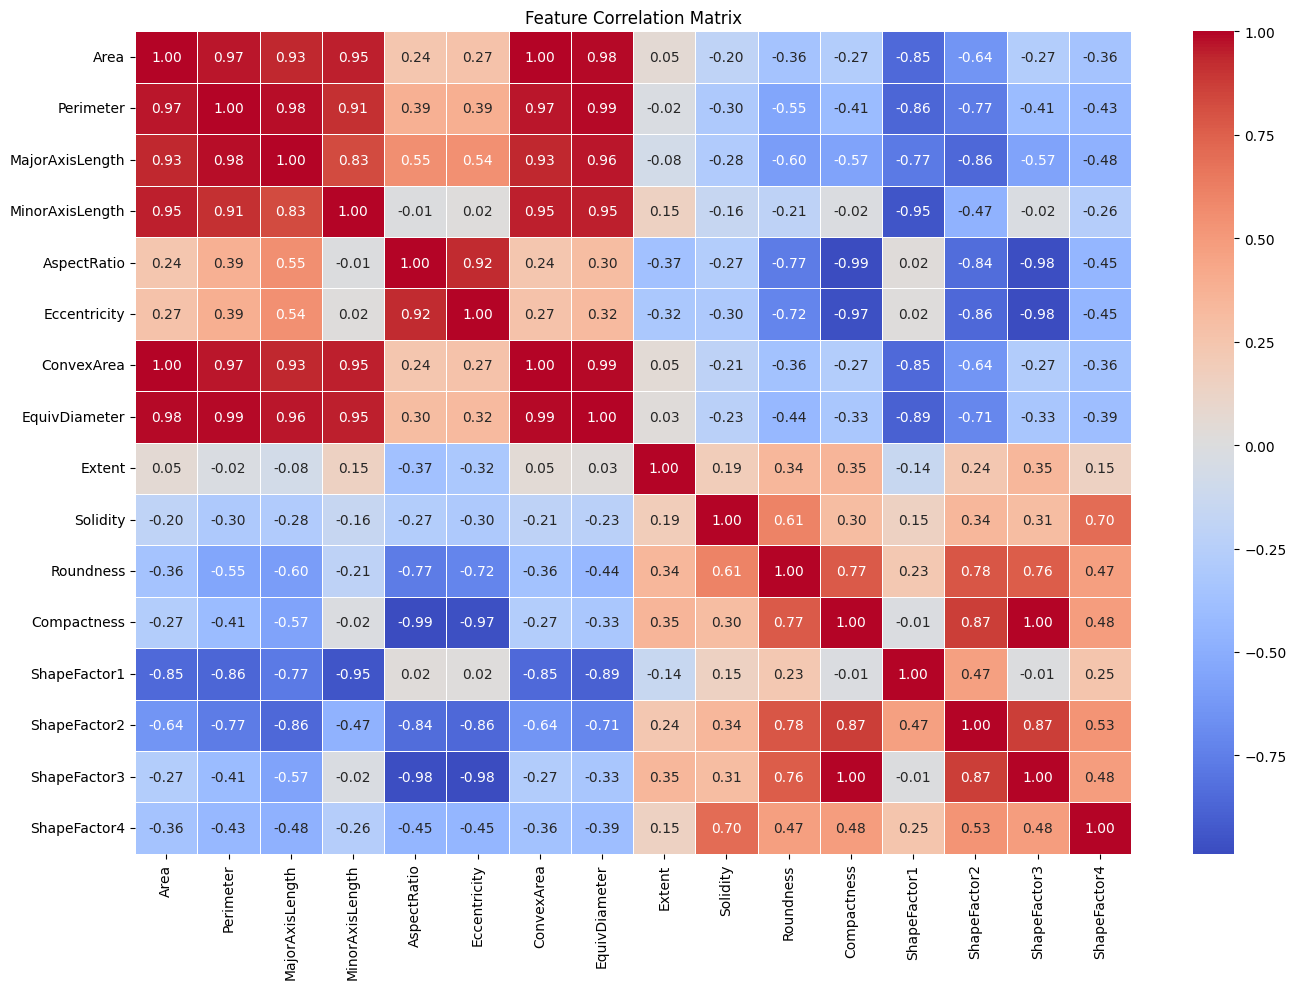

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

correlation = X.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [8]:
# Identify all rows belonging to duplicate groups
duplicate_rows = df[df.duplicated(keep=False)]

print("Rows involved in duplicate groups:",
      len(duplicate_rows))

print("Excess duplicate rows:",
      df.duplicated().sum())

print("\nDuplicate records:")
display(duplicate_rows.sort_values('Class').head(20))

Rows involved in duplicate groups: 136
Excess duplicate rows: 68

Duplicate records:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
5504,33518,702.956,277.571399,154.305581,1.798842,0.831240,34023,206.582775,0.808383,0.985157,0.852377,0.744251,0.008281,0.001567,0.553909,0.996396,HOROZ
7011,59442,975.979,402.887444,190.149460,2.118794,0.881616,60289,275.107079,0.732468,0.985951,0.784192,0.682839,0.006778,0.000909,0.466268,0.987927,HOROZ
7010,59442,975.979,402.887444,190.149460,2.118794,0.881616,60289,275.107079,0.732468,0.985951,0.784192,0.682839,0.006778,0.000909,0.466268,0.987927,HOROZ
6983,59105,957.363,372.981361,205.545240,1.814595,0.834448,60667,274.326126,0.757630,0.974253,0.810365,0.735496,0.006310,0.001139,0.540954,0.981612,HOROZ
6982,59105,957.363,372.981361,205.545240,1.814595,0.834448,60667,274.326126,0.757630,0.974253,0.810365,0.735496,0.006310,0.001139,0.540954,0.981612,HOROZ
6971,58891,966.204,397.793919,189.528762,2.098858,0.879202,59522,273.829053,0.601420,0.989399,0.792722,0.688369,0.006755,0.000936,0.473852,0.994548,HOROZ
6970,58891,966.204,397.793919,189.528762,2.098858,0.879202,59522,273.829053,0.601420,0.989399,0.792722,0.688369,0.006755,0.000936,0.473852,0.994548,HOROZ
6891,57886,985.808,389.588416,189.938594,2.051128,0.873103,58882,271.482493,0.777098,0.983085,0.748512,0.696844,0.006730,0.000979,0.485592,0.996012,HOROZ
6890,57886,985.808,389.588416,189.938594,2.051128,0.873103,58882,271.482493,0.777098,0.983085,0.748512,0.696844,0.006730,0.000979,0.485592,0.996012,HOROZ
6803,57029,953.664,388.137971,187.927020,2.065365,0.874971,57971,269.465356,0.784065,0.983750,0.787979,0.694251,0.006806,0.000975,0.481985,0.995475,HOROZ


In [9]:
# Check duplicate feature combinations
feature_duplicates = df[
    df.duplicated(subset=X.columns, keep=False)
]

# Find feature combinations associated with multiple classes
class_counts = (
    feature_duplicates.groupby(list(X.columns))['Class']
    .nunique()
)

conflicts = class_counts[class_counts > 1]

print("Feature combinations with conflicting labels:",
      len(conflicts))

Feature combinations with conflicting labels: 0


In [10]:
df_clean = df.drop_duplicates().copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Duplicates remaining:", df_clean.duplicated().sum())

Original dataset: (13611, 17)
Cleaned dataset: (13543, 17)
Duplicates remaining: 0


In [11]:
# descriptive Stats
display(X.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.285,29324.096,20420.000,36328.000,44652.000,61332.000,254616.000
Perimeter,13611.0,855.283,214.290,524.736,703.524,794.941,977.213,1985.370
MajorAxisLength,13611.0,320.142,85.694,183.601,253.304,296.883,376.495,738.860
MinorAxisLength,13611.0,202.271,44.970,122.513,175.848,192.432,217.032,460.198
AspectRatio,13611.0,1.583,0.247,1.025,1.432,1.551,1.707,2.430
Eccentricity,13611.0,0.751,0.092,0.219,0.716,0.764,0.810,0.911
ConvexArea,13611.0,53768.200,29774.916,20684.000,36714.500,45178.000,62294.000,263261.000
EquivDiameter,13611.0,253.064,59.177,161.244,215.068,238.438,279.446,569.374
Extent,13611.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13611.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


In [12]:
# Recreate X and y from cleaned dataset
X = df_clean.drop(columns=['Class'])
y = df_clean['Class']

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.describe().T.round(3))

X shape: (13543, 16)
y shape: (13543,)


,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.460,29392.438,20420.000,36282.500,44580.000,61382.000,254616.000
Perimeter,13543.0,854.993,214.723,524.736,703.230,793.896,977.147,1985.370
MajorAxisLength,13543.0,319.896,85.809,183.601,253.087,296.405,376.312,738.860
MinorAxisLength,13543.0,202.365,45.052,122.513,175.886,192.491,217.245,460.198
AspectRatio,13543.0,1.581,0.245,1.025,1.431,1.550,1.704,2.430
Eccentricity,13543.0,0.750,0.092,0.219,0.715,0.764,0.810,0.911
ConvexArea,13543.0,53767.987,29844.249,20684.000,36673.000,45122.000,62360.000,263261.000
EquivDiameter,13543.0,253.034,59.308,161.244,214.933,238.246,279.560,569.374
Extent,13543.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13543.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


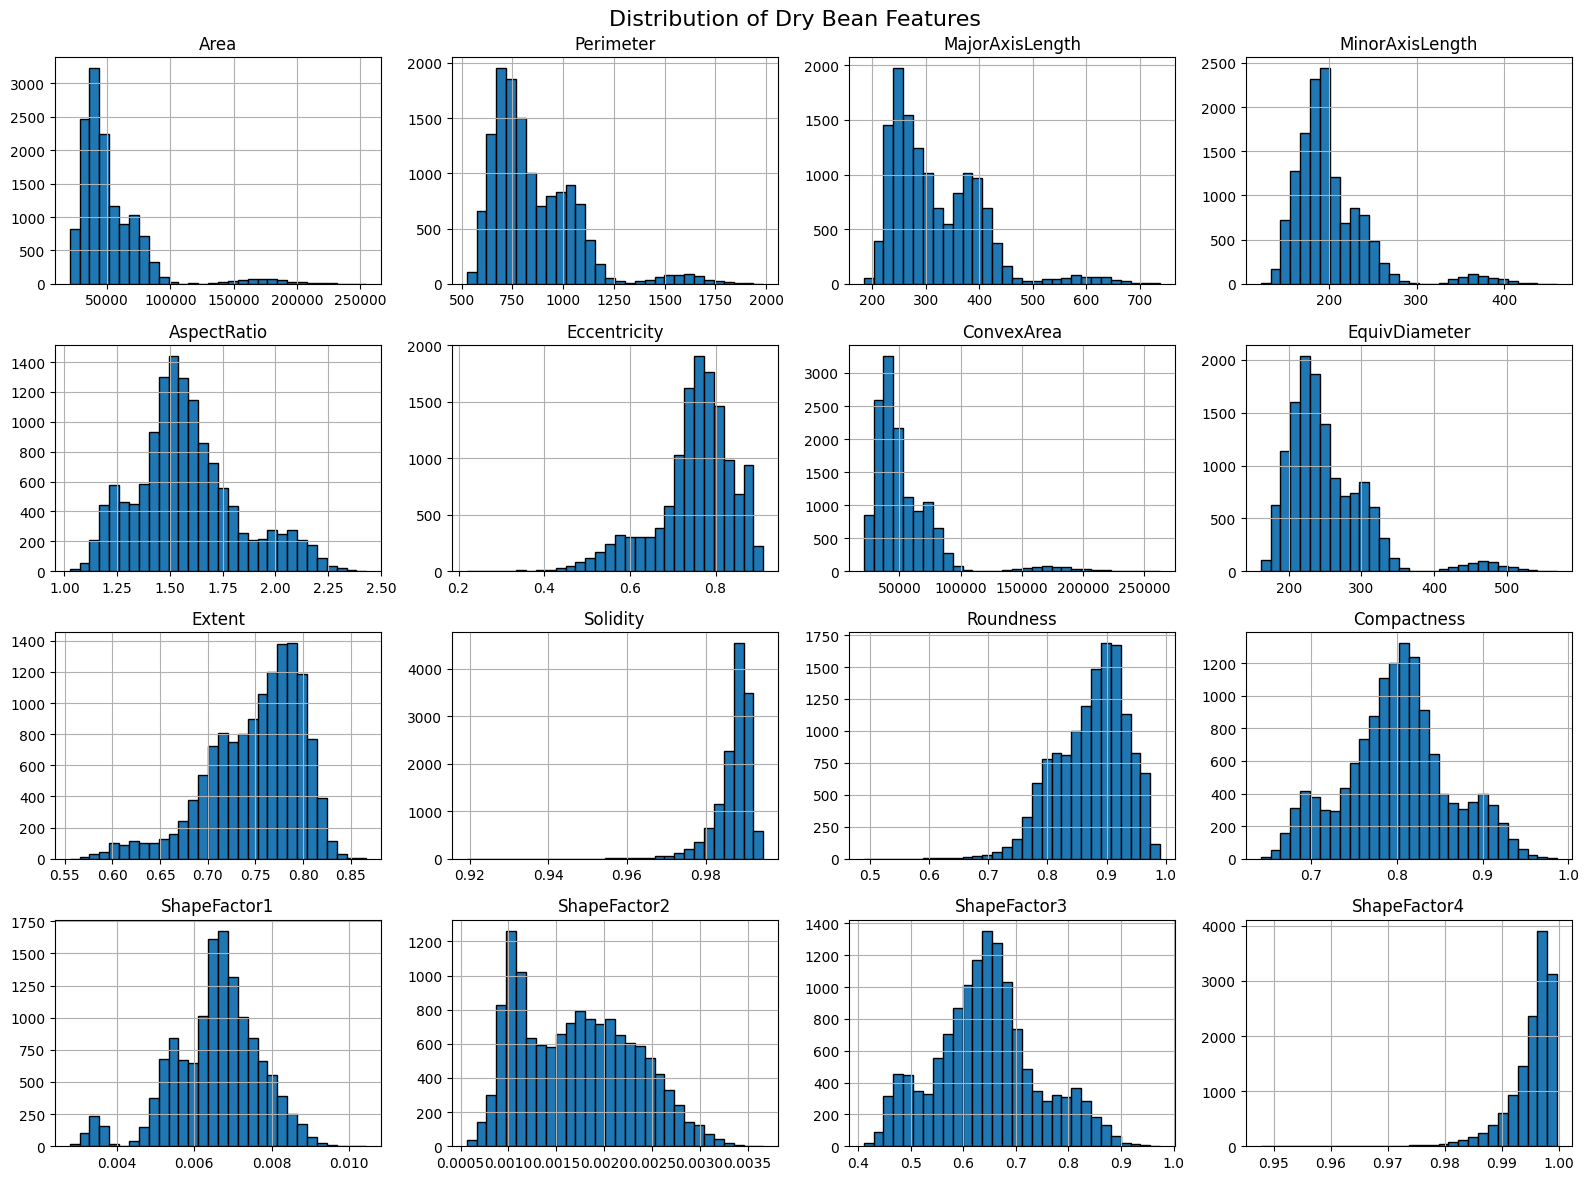

In [13]:
# Distribution
import matplotlib.pyplot as plt

X.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    "Distribution of Dry Bean Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

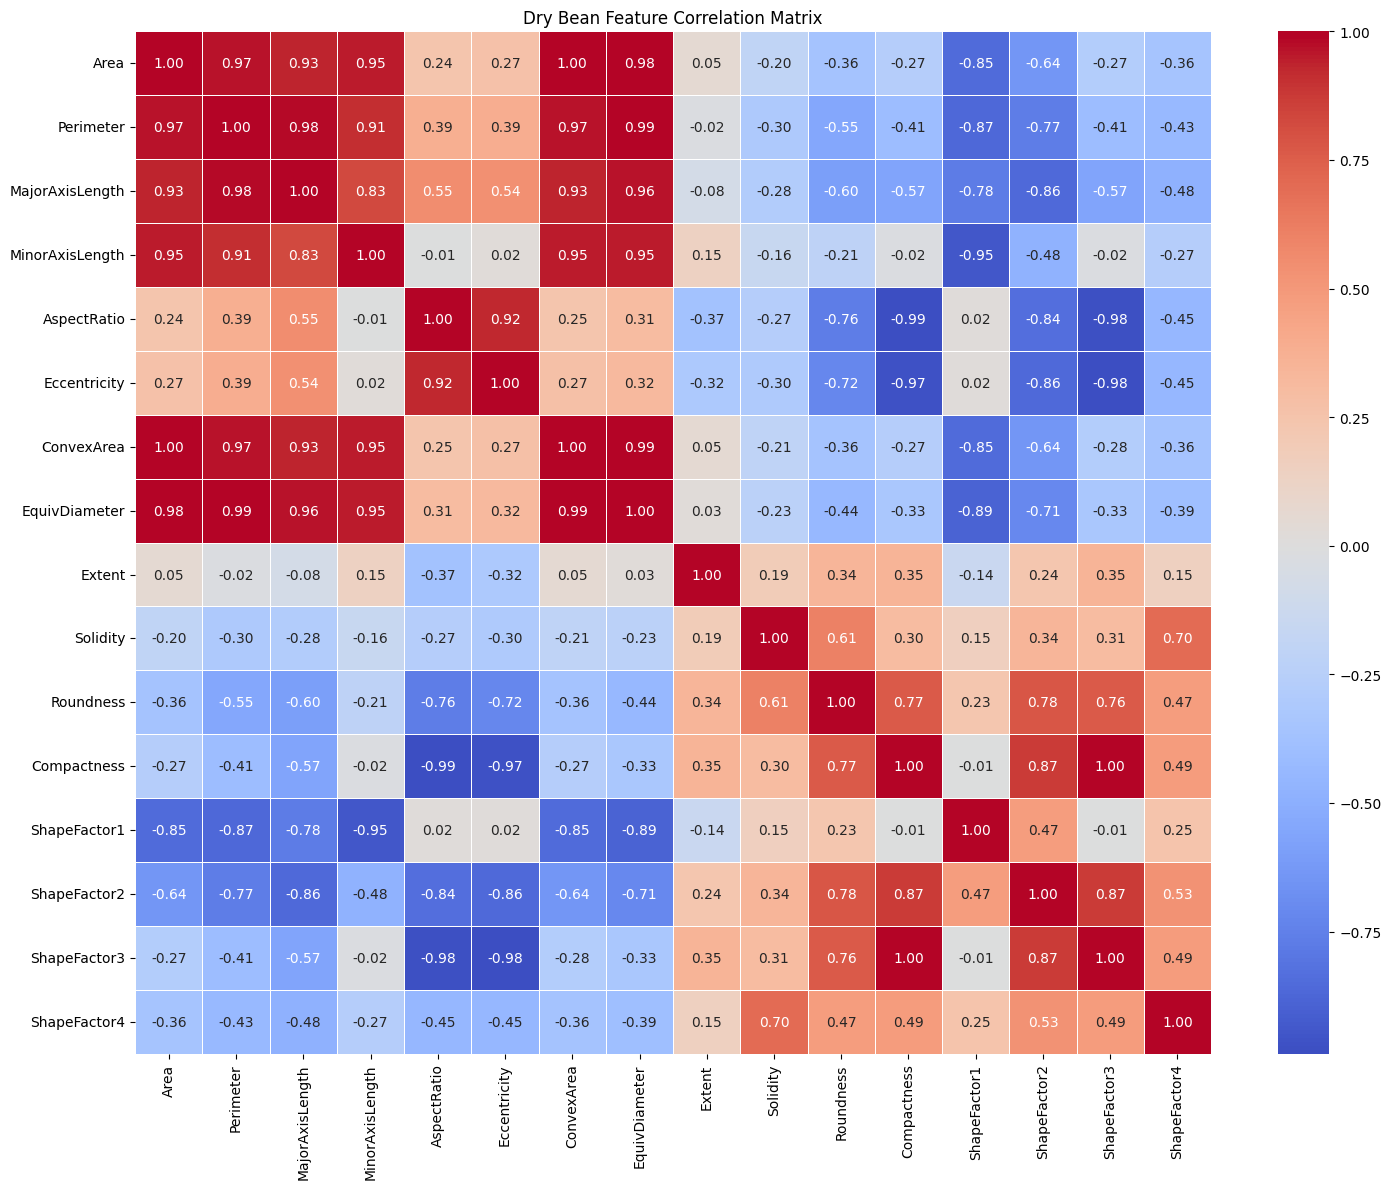

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate Pearson correlation
correlation = X.corr(method='pearson')

# Plot correlation matrix
plt.figure(figsize=(15, 12))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title("Dry Bean Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [15]:
# Calculate quartiles
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Count outliers
outlier_counts = (
    (X < lower_bound) | (X > upper_bound)
).sum()

# Display results
outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_counts,
    'Outlier Percentage': (
        outlier_counts / len(X) * 100
    ).round(2)
})

display(outlier_summary.sort_values(
    'Outlier Count',
    ascending=False
))

,Outlier Count,Outlier Percentage
Eccentricity,833,6.15
Solidity,774,5.72
ShapeFactor4,760,5.61
MinorAxisLength,567,4.19
Area,551,4.07
ConvexArea,549,4.05
ShapeFactor1,533,3.94
EquivDiameter,526,3.88
Perimeter,500,3.69
AspectRatio,485,3.58


In [16]:
# Identify records with at least one IQR outlier
outlier_mask = (
    (X < lower_bound) |
    (X > upper_bound)
).any(axis=1)

print("Total observations:", len(X))

print("Unique observations with potential outliers:",
      outlier_mask.sum())

print("Percentage of observations:",
      round(outlier_mask.mean() * 100, 2), "%")

Total observations: 13543
Unique observations with potential outliers: 3004
Percentage of observations: 22.18 %


In [18]:
from sklearn.model_selection import train_test_split

# Separate features and target from cleaned dataset
X = df_clean.drop(columns=['Class'])
y = df_clean['Class']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (10834, 16)
Testing features: (2709, 16)
Training target: (10834,)
Testing target: (2709,)


In [39]:
# Compare class distributions
distribution = pd.DataFrame({
    'Original (%)': y.value_counts(normalize=True) * 100,
    'Training (%)': y_train.value_counts(normalize=True) * 100,
    'Testing (%)': y_test.value_counts(normalize=True) * 100
})

display(distribution.round(2))

,Original (%),Training (%),Testing (%)
Class,,,
DERMASON,26.18,26.19,26.17
SIRA,19.46,19.47,19.45
SEKER,14.97,14.96,14.99
HOROZ,13.73,13.73,13.73
CALI,12.04,12.04,12.03
BARBUNYA,9.76,9.76,9.78
BOMBAY,3.85,3.86,3.84


In [41]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

log_reg_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        solver='lbfgs',
        max_iter=2000,
        random_state=42
    ))
])

log_reg_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

# Predict class labels
y_pred_lr = log_reg_model.predict(X_test)

# Predict class probabilities
y_prob_lr = log_reg_model.predict_proba(X_test)

print("Predictions:", y_pred_lr[:10])
print("\nProbability matrix shape:", y_prob_lr.shape)

Logistic Regression training completed!
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER' 'DERMASON' 'DERMASON'
 'DERMASON' 'BARBUNYA' 'DERMASON']

Probability matrix shape: (2709, 7)


In [43]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Calculate evaluation metrics
lr_results = {
    'Accuracy': accuracy_score(y_test, y_pred_lr),

    'AUC': roc_auc_score(
        y_test,
        y_prob_lr,
        multi_class='ovr',
        average='weighted'
    ),

    'Precision': precision_score(
        y_test,
        y_pred_lr,
        average='weighted',
        zero_division=0
    ),

    'Recall': recall_score(
        y_test,
        y_pred_lr,
        average='weighted',
        zero_division=0
    ),

    'F1 Score': f1_score(
        y_test,
        y_pred_lr,
        average='weighted',
        zero_division=0
    ),

    'MCC': matthews_corrcoef(y_test, y_pred_lr)
}

print("Logistic Regression Results")

for metric, value in lr_results.items():
    print(f"{metric}: {value:.4f}")

Logistic Regression Results
Accuracy: 0.9195
AUC: 0.9935
Precision: 0.9201
Recall: 0.9195
F1 Score: 0.9197
MCC: 0.9028


In [47]:
#Now step 2 on Decision tree classifier
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)
dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")

# Predicted class labels
y_pred_dt = dt_model.predict(X_test)

# Predicted class probabilities
y_prob_dt = dt_model.predict_proba(X_test)

print("Predictions:", y_pred_dt[:10])
print("Probability matrix shape:", y_prob_dt.shape)

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

dt_results = {
    'Accuracy': accuracy_score(y_test, y_pred_dt),

    'AUC': roc_auc_score(
        y_test,
        y_prob_dt,
        multi_class='ovr',
        average='weighted'
    ),

    'Precision': precision_score(
        y_test,
        y_pred_dt,
        average='weighted',
        zero_division=0
    ),

    'Recall': recall_score(
        y_test,
        y_pred_dt,
        average='weighted',
        zero_division=0
    ),

    'F1 Score': f1_score(
        y_test,
        y_pred_dt,
        average='weighted',
        zero_division=0
    ),

    'MCC': matthews_corrcoef(y_test, y_pred_dt)
}

print("Decision Tree Results")

for metric, value in dt_results.items():
    print(f"{metric}: {value:.4f}")

Decision Tree training completed!
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER' 'DERMASON' 'DERMASON'
 'DERMASON' 'BARBUNYA' 'DERMASON']
Probability matrix shape: (2709, 7)
Decision Tree Results
Accuracy: 0.8955
AUC: 0.9357
Precision: 0.8954
Recall: 0.8955
F1 Score: 0.8953
MCC: 0.8737


In [49]:
# Step 3 with KNN
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(
        n_neighbors=5,
        weights='uniform',
        metric='minkowski',
        p=2
    ))
])

knn_model.fit(X_train, y_train)


# Predict class labels
y_pred_knn = knn_model.predict(X_test)

# Predict class probabilities
y_prob_knn = knn_model.predict_proba(X_test)

print("Predictions:", y_pred_knn[:10])
print("Probability matrix shape:", y_prob_knn.shape)
print("KNN training completed!")

Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER' 'DERMASON' 'DERMASON'
 'DERMASON' 'BARBUNYA' 'DERMASON']
Probability matrix shape: (2709, 7)
KNN training completed!


In [51]:
knn_results = {
    'Accuracy': accuracy_score(y_test, y_pred_knn),

    'AUC': roc_auc_score(
        y_test,
        y_prob_knn,
        multi_class='ovr',
        average='weighted'
    ),

    'Precision': precision_score(
        y_test,
        y_pred_knn,
        average='weighted',
        zero_division=0
    ),

    'Recall': recall_score(
        y_test,
        y_pred_knn,
        average='weighted',
        zero_division=0
    ),

    'F1 Score': f1_score(
        y_test,
        y_pred_knn,
        average='weighted',
        zero_division=0
    ),

    'MCC': matthews_corrcoef(y_test, y_pred_knn)
}

print("KNN Results")

for metric, value in knn_results.items():
    print(f"{metric}: {value:.4f}")

KNN Results
Accuracy: 0.9155
AUC: 0.9811
Precision: 0.9163
Recall: 0.9155
F1 Score: 0.9157
MCC: 0.8978


In [53]:
# Step 4 Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

print("Gaussian Naive Bayes training completed!")

# Predict class labels
y_pred_nb = nb_model.predict(X_test)

# Predict class probabilities
y_prob_nb = nb_model.predict_proba(X_test)

print("Predictions:", y_pred_nb[:10])

print("Probability matrix shape:", y_prob_nb.shape)

Gaussian Naive Bayes training completed!
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER' 'SEKER' 'DERMASON'
 'DERMASON' 'BARBUNYA' 'DERMASON']
Probability matrix shape: (2709, 7)


In [55]:
nb_results = {
    'Accuracy': accuracy_score(y_test, y_pred_nb),

    'AUC': roc_auc_score(
        y_test,
        y_prob_nb,
        multi_class='ovr',
        average='weighted'
    ),

    'Precision': precision_score(
        y_test,
        y_pred_nb,
        average='weighted',
        zero_division=0
    ),

    'Recall': recall_score(
        y_test,
        y_pred_nb,
        average='weighted',
        zero_division=0
    ),

    'F1 Score': f1_score(
        y_test,
        y_pred_nb,
        average='weighted',
        zero_division=0
    ),

    'MCC': matthews_corrcoef(y_test, y_pred_nb)
}

print("Gaussian Naive Bayes Results")

for metric, value in nb_results.items():
    print(f"{metric}: {value:.4f}")

Gaussian Naive Bayes Results
Accuracy: 0.7630
AUC: 0.9644
Precision: 0.7647
Recall: 0.7630
F1 Score: 0.7607
MCC: 0.7143


In [57]:
# STep 5 using SVM

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        probability=True,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

print("SVM training completed!")

# Predicted classes
y_pred_svm = svm_model.predict(X_test)

# Predicted probabilities
y_prob_svm = svm_model.predict_proba(X_test)

print("Predictions:", y_pred_svm[:10])

print("Probability matrix shape:", y_prob_svm.shape)

/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training completed!
Predictions: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER' 'DERMASON' 'DERMASON'
 'DERMASON' 'BARBUNYA' 'DERMASON']
Probability matrix shape: (2709, 7)


In [59]:
svm_results = {
    'Accuracy': accuracy_score(y_test, y_pred_svm),

    'AUC': roc_auc_score(
        y_test,
        y_prob_svm,
        multi_class='ovr',
        average='weighted'
    ),

    'Precision': precision_score(
        y_test,
        y_pred_svm,
        average='weighted',
        zero_division=0
    ),

    'Recall': recall_score(
        y_test,
        y_pred_svm,
        average='weighted',
        zero_division=0
    ),

    'F1 Score': f1_score(
        y_test,
        y_pred_svm,
        average='weighted',
        zero_division=0
    ),

    'MCC': matthews_corrcoef(y_test, y_pred_svm)
}

print("SVM Results")

for metric, value in svm_results.items():
    print(f"{metric}: {value:.4f}")

SVM Results
Accuracy: 0.9210
AUC: 0.9933
Precision: 0.9214
Recall: 0.9210
F1 Score: 0.9211
MCC: 0.9045


In [61]:
import pandas as pd

# Collect results from all five models
all_results = {
    'Logistic Regression': lr_results,
    'Decision Tree': dt_results,
    'KNN': knn_results,
    'Naive Bayes': nb_results,
    'SVM': svm_results
}

# Create comparison dataframe
comparison_df = pd.DataFrame(all_results).T

# Display results
display(comparison_df.round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.9195,0.9935,0.9201,0.9195,0.9197,0.9028
Decision Tree,0.8955,0.9357,0.8954,0.8955,0.8953,0.8737
KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143
SVM,0.9210,0.9933,0.9214,0.9210,0.9211,0.9045


In [63]:
comparison_df.to_csv(
    'model_comparison.csv',
    index=True
)

In [65]:
from sklearn.metrics import classification_report

# Store predictions
predictions = {
    'Logistic Regression': y_pred_lr,
    'Decision Tree': y_pred_dt,
    'KNN': y_pred_knn,
    'Naive Bayes': y_pred_nb,
    'SVM': y_pred_svm
}

# Generate classification reports
for model_name, predictions_model in predictions.items():

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    print(classification_report(
        y_test,
        predictions_model,
        digits=4,
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

    BARBUNYA     0.9255    0.8906    0.9077       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9110    0.9417    0.9261       326
    DERMASON     0.9265    0.9069    0.9166       709
       HOROZ     0.9643    0.9435    0.9538       372
       SEKER     0.9319    0.9433    0.9376       406
        SIRA     0.8585    0.8861    0.8721       527

    accuracy                         0.9195      2709
   macro avg     0.9311    0.9303    0.9306      2709
weighted avg     0.9201    0.9195    0.9197      2709


Decision Tree
              precision    recall  f1-score   support

    BARBUNYA     0.8810    0.8943    0.8876       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.8946    0.9110    0.9027       326
    DERMASON     0.8887    0.9013    0.8950       709
       HOROZ     0.9528    0.9220    0.9372       372
       SEKER     0.9069    0.9360    0.921

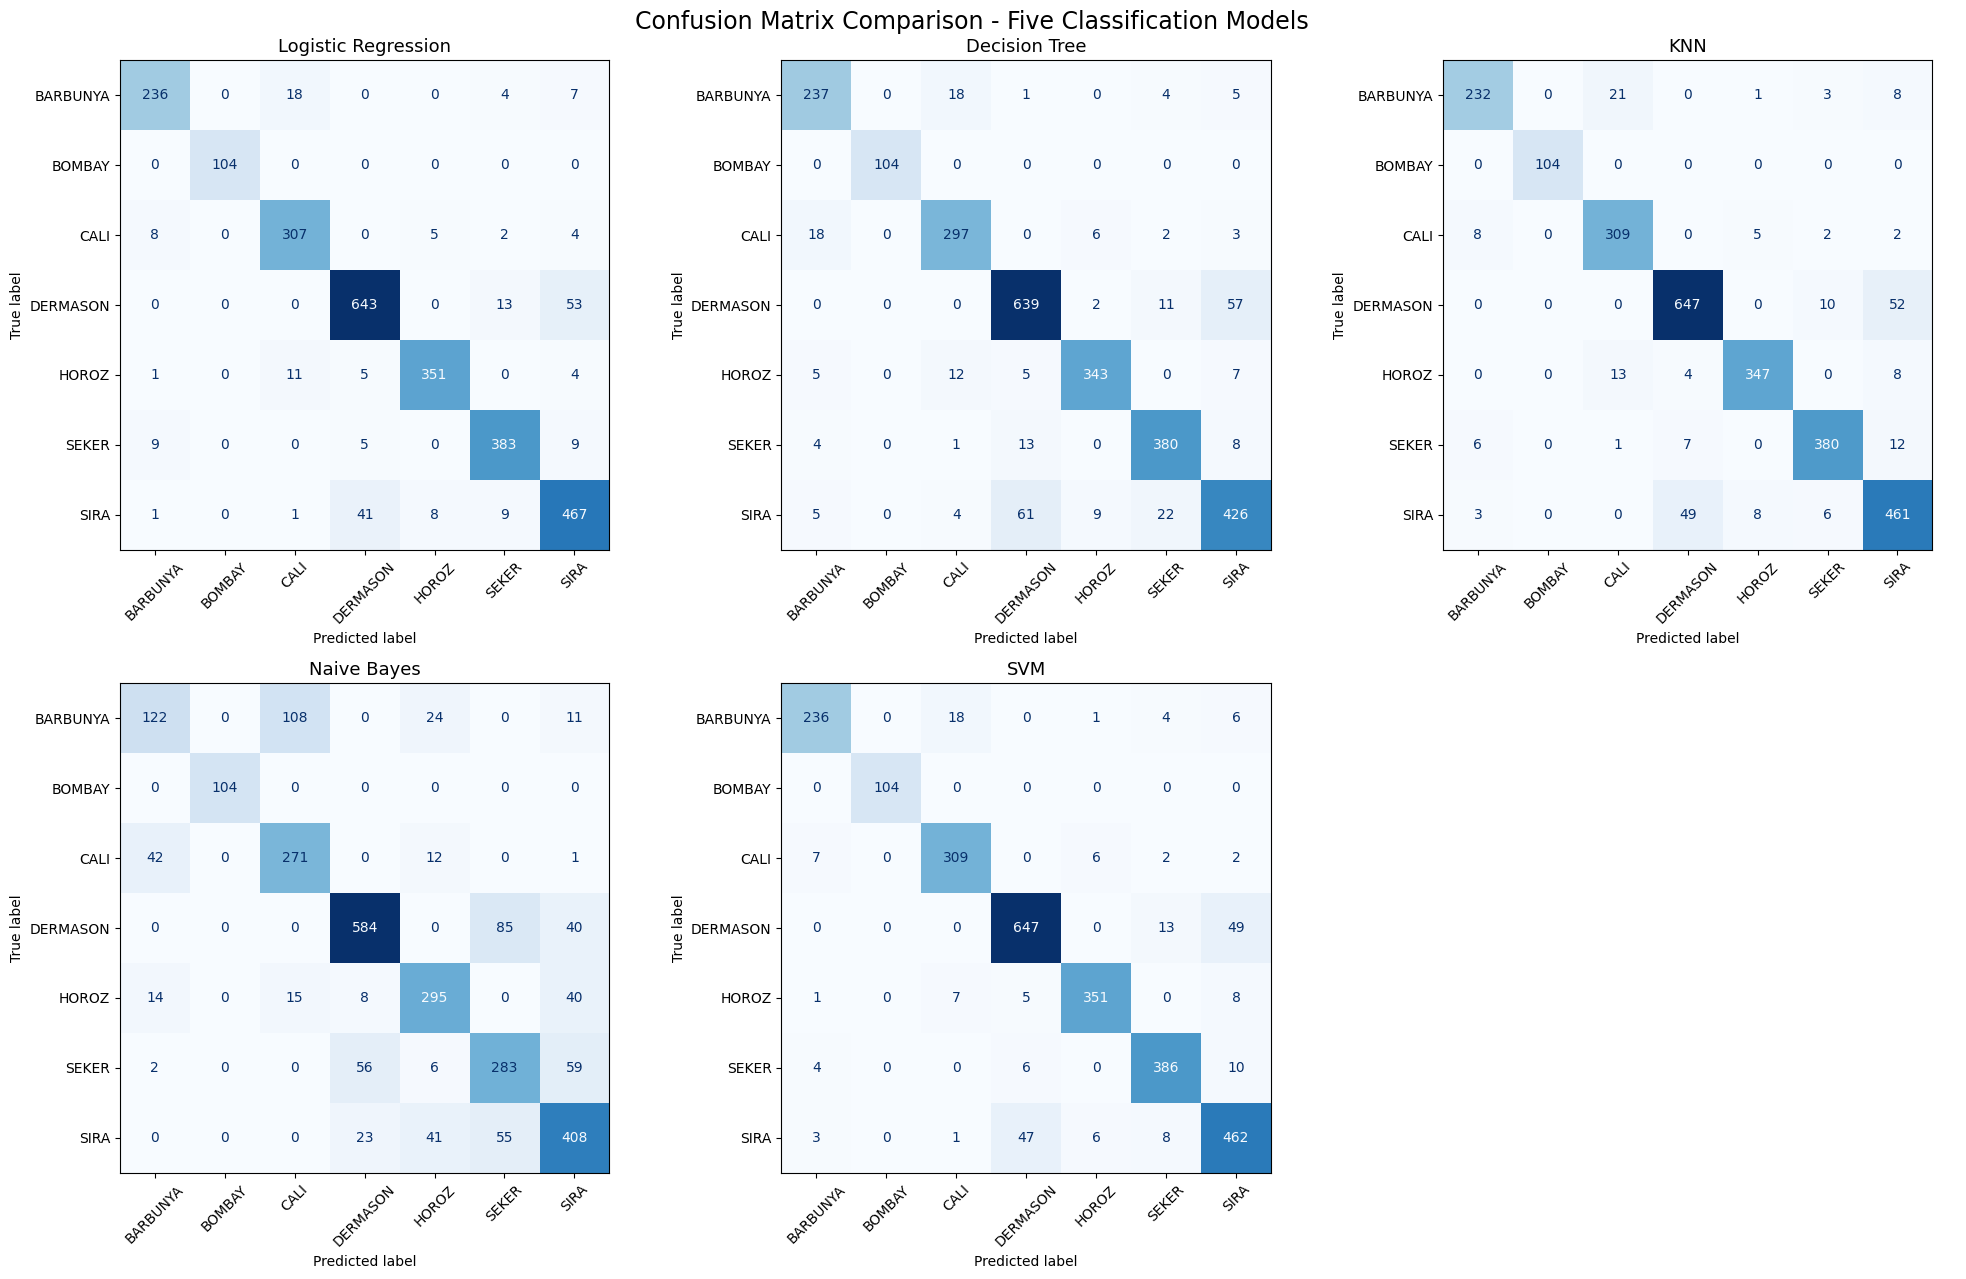

In [67]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Define all five predictions
predictions = {
    'Logistic Regression': y_pred_lr,
    'Decision Tree': y_pred_dt,
    'KNN': y_pred_knn,
    'Naive Bayes': y_pred_nb,
    'SVM': y_pred_svm
}

# Consistent class ordering
class_names = sorted(y_test.unique())

# Create 5 confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(20, 13))

axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(predictions.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=class_names,
        display_labels=class_names,
        cmap='Blues',
        values_format='d',
        xticks_rotation=45,
        colorbar=False,
        ax=axes[i]
    )

    axes[i].set_title(model_name, fontsize=13)

# Hide the unused sixth plot
axes[5].axis('off')

plt.suptitle(
    "Confusion Matrix Comparison - Five Classification Models",
    fontsize=17
)

plt.tight_layout()
plt.show()

In [69]:
import os
import joblib

# Create models directory
os.makedirs("models", exist_ok=True)

In [71]:
# Dictionary containing trained models
models = {
    "logistic_regression": log_reg_model,
    "decision_tree": dt_model,
    "knn": knn_model,
    "naive_bayes": nb_model,
    "svm": svm_model
}

# Save each model
for model_name, model in models.items():

    filename = f"models/{model_name}.joblib"

    joblib.dump(model, filename)

    print(f"Saved: {filename}")

Saved: models/logistic_regression.joblib
Saved: models/decision_tree.joblib
Saved: models/knn.joblib
Saved: models/naive_bayes.joblib
Saved: models/svm.joblib


In [73]:
# Load and verify saved models

loaded_models = {}

for model_name in models.keys():

    filename = f"models/{model_name}.joblib"

    loaded_models[model_name] = joblib.load(filename)

    print(f"Loaded successfully: {model_name}")

Loaded successfully: logistic_regression
Loaded successfully: decision_tree
Loaded successfully: knn
Loaded successfully: naive_bayes
Loaded successfully: svm


In [75]:
# Verify predictions against original models

for model_name in models.keys():

    original_predictions = models[model_name].predict(X_test)

    loaded_predictions = loaded_models[model_name].predict(X_test)

    print(
        model_name,
        "Identical predictions:",
        (original_predictions == loaded_predictions).all()
    )

logistic_regression Identical predictions: True
decision_tree Identical predictions: True
knn Identical predictions: True
naive_bayes Identical predictions: True
svm Identical predictions: True


In [77]:
# Combine test features and target

test_data = X_test.copy()

test_data['Class'] = y_test

# Save CSV
test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test data saved successfully!")
print("Shape:", test_data.shape)

display(test_data.head())

Test data saved successfully!
Shape: (2709, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
1223,40512,737.636,248.202030,208.525151,1.190274,0.542365,40973,227.115566,0.744268,0.988749,0.935641,0.915043,0.006127,0.002650,0.837304,0.996621,SEKER
11837,31890,660.655,250.417300,162.522503,1.540816,0.760783,32240,201.503372,0.801962,0.989144,0.918153,0.804670,0.007853,0.002031,0.647494,0.997670,DERMASON
12127,33107,671.869,244.728317,172.938116,1.415121,0.707560,33506,205.312303,0.798683,0.988092,0.921638,0.838940,0.007392,0.002259,0.703820,0.995990,DERMASON
7186,61684,984.878,412.115648,191.473279,2.152340,0.885515,62303,280.247227,0.784724,0.990065,0.799130,0.680021,0.006681,0.000881,0.462428,0.995303,HOROZ
638,37189,700.253,243.343401,194.910062,1.248491,0.598708,37534,217.601713,0.784826,0.990808,0.953047,0.894217,0.006543,0.002581,0.799623,0.998322,SEKER


In [79]:
import pandas as pd

# Read the saved test CSV
test_check = pd.read_csv("test_data.csv")

print("Dataset shape:", test_check.shape)

print("\nColumn names:")
print(test_check.columns.tolist())

print("\nTarget distribution:")
print(test_check['Class'].value_counts())

Dataset shape: (2709, 17)

Column names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Target distribution:
Class
DERMASON    709
SIRA        527
SEKER       406
HOROZ       372
CALI        326
BARBUNYA    265
BOMBAY      104
Name: count, dtype: int64


In [81]:
import os

print("Saved model files:")

for file in os.listdir("models"):
    print(file)

Saved model files:
logistic_regression.joblib
decision_tree.joblib
knn.joblib
naive_bayes.joblib
svm.joblib


In [83]:
import joblib
import numpy as np

loaded_models = {}

for name, original_model in models.items():

    path = f"models/{name}.joblib"

    # Load saved model
    loaded_model = joblib.load(path)
    loaded_models[name] = loaded_model

    # Compare predictions
    original_pred = original_model.predict(X_test)
    loaded_pred = loaded_model.predict(X_test)

    identical = np.array_equal(original_pred, loaded_pred)

    print(f"{name}: {identical}")

logistic_regression: True
decision_tree: True
knn: True
naive_bayes: True
svm: True


In [2]:

%%writefile app.py

from pathlib import Path

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)


# ==================================================
# 1. PAGE CONFIGURATION
# ==================================================

st.set_page_config(
    page_title="Dry Bean ML Dashboard",
    page_icon="🌱",
    layout="wide"
)

st.title("🌱 Dry Bean Classification Dashboard")

st.caption(
    "BITS Pilani | M.Tech Artificial Intelligence & Machine Learning "
    "| Machine Learning Assignment 2"
)

st.write(
    "Evaluate and compare five machine learning classifiers "
    "using the Dry Bean dataset."
)


# ==================================================
# 2. PROJECT CONFIGURATION
# ==================================================

BASE_DIR = Path(__file__).resolve().parent

TEST_DATA_PATH = BASE_DIR / "test_data.csv"

FEATURES = [
    "Area",
    "Perimeter",
    "MajorAxisLength",
    "MinorAxisLength",
    "AspectRatio",
    "Eccentricity",
    "ConvexArea",
    "EquivDiameter",
    "Extent",
    "Solidity",
    "Roundness",
    "Compactness",
    "ShapeFactor1",
    "ShapeFactor2",
    "ShapeFactor3",
    "ShapeFactor4"
]

TARGET = "Class"

MODEL_FILES = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib"
}


# ==================================================
# 3. LOAD ALL FIVE SAVED MODELS
# ==================================================

@st.cache_resource
def load_models():

    loaded_models = {}

    for model_name, filename in MODEL_FILES.items():

        model_path = BASE_DIR / "models" / filename

        if not model_path.exists():
            raise FileNotFoundError(
                f"Missing model file: {filename}"
            )

        loaded_models[model_name] = joblib.load(
            model_path
        )

    return loaded_models


try:

    models = load_models()

except Exception as error:

    st.error(f"Model loading failed: {error}")
    st.stop()


# Use the saved model's class ordering
CLASS_NAMES = models["Logistic Regression"].classes_


# ==================================================
# 4. SIDEBAR - DATASET SELECTION
# ==================================================

st.sidebar.title("Evaluation Settings")

st.sidebar.subheader("Select Dataset")

uploaded_file = st.sidebar.file_uploader(
    "Upload your own test CSV (optional)",
    type=["csv"]
)

if uploaded_file is None:

    st.sidebar.success(
        "Using preloaded assignment test dataset"
    )

    if not TEST_DATA_PATH.exists():

        st.error(
            "Preloaded test_data.csv was not found "
            "in the project directory."
        )

        st.stop()

    df = pd.read_csv(TEST_DATA_PATH)

    dataset_name = "Preloaded Test Dataset"

else:

    try:

        df = pd.read_csv(uploaded_file)

        dataset_name = uploaded_file.name

        st.sidebar.info(
            f"Using uploaded dataset: {dataset_name}"
        )

    except Exception as error:

        st.error(f"Unable to read uploaded CSV: {error}")
        st.stop()


st.sidebar.markdown("---")

st.sidebar.write("**Available classifiers**")

for model_name in MODEL_FILES:
    st.sidebar.write(f"✓ {model_name}")

st.sidebar.markdown("---")

st.sidebar.caption(
    "All models are pre-trained. "
    "Uploaded datasets are used only for evaluation."
)


# ==================================================
# 5. VALIDATE THE DATASET
# ==================================================

required_columns = FEATURES + [TARGET]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:

    st.error(
        f"Missing required columns: {missing_columns}"
    )

    st.stop()


if df.empty:

    st.error("The uploaded dataset is empty.")
    st.stop()


if df[TARGET].isnull().any():

    st.error("Target column contains missing values.")
    st.stop()


# Select required features in training order
X = df[FEATURES].copy()

# Convert input features to numeric
for col in FEATURES:

    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )


# Check missing and invalid feature values
if X.isnull().any().any():

    st.error(
        "Input features contain missing or invalid values."
    )

    st.stop()


if not np.isfinite(X.to_numpy()).all():

    st.error("Input features contain infinite values.")
    st.stop()


# Normalize target label representation
y = df[TARGET].astype(str).str.strip().str.upper()


if (y == "").any():

    st.error("Target column contains empty labels.")
    st.stop()


# Validate class labels
unknown_classes = set(y.unique()) - set(CLASS_NAMES)

if unknown_classes:

    st.error(
        f"Unknown bean classes found: {unknown_classes}"
    )

    st.stop()


# ==================================================
# 6. DATASET OVERVIEW
# ==================================================

st.markdown("---")

st.header("Dataset Overview")

col1, col2, col3, col4 = st.columns(4)

col1.metric(
    "Observations",
    f"{len(df):,}"
)

col2.metric(
    "Input Features",
    len(FEATURES)
)

col3.metric(
    "Bean Classes",
    y.nunique()
)

col4.metric(
    "Classification Models",
    len(models)
)

st.caption(f"Current dataset: {dataset_name}")

with st.expander("Preview dataset and class distribution"):

    st.dataframe(
        df.head(10),
        use_container_width=True
    )

    st.write("Class distribution")

    st.bar_chart(
        y.value_counts()
    )


# ==================================================
# 7. EVALUATE ALL FIVE MODELS
# ==================================================

results = {}
predictions = {}
probabilities = {}

all_classes_present = set(y.unique()) == set(CLASS_NAMES)

for model_name, model in models.items():

    y_pred = model.predict(X)

    y_prob = model.predict_proba(X)

    predictions[model_name] = y_pred

    probabilities[model_name] = y_prob

    # AUC requires all seven target classes here
    if all_classes_present:

        auc = roc_auc_score(
            y,
            y_prob,
            labels=model.classes_,
            multi_class="ovr",
            average="weighted"
        )

    else:

        auc = np.nan

    results[model_name] = {

        "Accuracy": accuracy_score(
            y, y_pred
        ),

        "AUC": auc,

        "Precision": precision_score(
            y,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            y,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "F1 Score": f1_score(
            y,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "MCC": matthews_corrcoef(
            y,
            y_pred
        )
    }


# ==================================================
# 8. OVERALL MODEL COMPARISON
# ==================================================

st.markdown("---")

st.header("Overall Model Comparison")

comparison_df = pd.DataFrame(results).T

st.subheader("Evaluation Metrics")

st.dataframe(
    comparison_df.style.format(
        "{:.4f}",
        na_rep="N/A"
    ),
    use_container_width=True
)

# Identify metric leaders
metric_columns = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

best_accuracy = comparison_df["Accuracy"].idxmax()

best_auc = comparison_df["AUC"].idxmax()

col1, col2 = st.columns(2)

col1.success(
    f"Highest Accuracy: {best_accuracy} "
    f"({comparison_df.loc[best_accuracy, 'Accuracy']:.4f})"
)

if not pd.isna(comparison_df["AUC"].max()):

    col2.info(
        f"Highest AUC: {best_auc} "
        f"({comparison_df.loc[best_auc, 'AUC']:.4f})"
    )

else:

    col2.info(
        "AUC unavailable: all seven classes "
        "are not present in the dataset."
    )


# ==================================================
# 9. COMPARE ALL MODELS GRAPHICALLY
# ==================================================

st.subheader("Performance Metrics Comparison")

st.caption(
    "All six evaluation metrics are displayed together."
)

st.bar_chart(
    comparison_df[metric_columns]
)


# ==================================================
# 10. MODEL-WISE DETAILED RESULTS
# ==================================================

st.markdown("---")

st.header("Individual Model Analysis")

st.write(
    "Select a model tab to examine its performance, "
    "confusion matrix and classification report."
)

model_tabs = st.tabs(list(models.keys()))

for tab, (model_name, model) in zip(
    model_tabs,
    models.items()
):

    with tab:

        st.subheader(model_name)

        model_metrics = results[model_name]

        # Display six evaluation metrics
        metric_cols = st.columns(6)

        for col, metric in zip(
            metric_cols,
            metric_columns
        ):

            value = model_metrics[metric]

            display_value = (
                "N/A"
                if pd.isna(value)
                else f"{value:.4f}"
            )

            col.metric(
                metric,
                display_value
            )

        # Confusion matrix
        st.markdown("#### Confusion Matrix")

        cm = confusion_matrix(
            y,
            predictions[model_name],
            labels=CLASS_NAMES
        )

        fig, ax = plt.subplots(
            figsize=(9, 7)
        )

        display = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=CLASS_NAMES
        )

        display.plot(
            ax=ax,
            cmap="Blues",
            values_format="d",
            xticks_rotation=45,
            colorbar=False
        )

        plt.title(
            f"Confusion Matrix - {model_name}"
        )

        plt.tight_layout()

        st.pyplot(fig)

        plt.close(fig)

        # Classification report
        st.markdown("#### Classification Report")

        report = classification_report(
            y,
            predictions[model_name],
            labels=CLASS_NAMES,
            target_names=CLASS_NAMES,
            output_dict=True,
            zero_division=0
        )

        report_df = pd.DataFrame(
            report
        ).T

        st.dataframe(
            report_df.style.format("{:.4f}"),
            use_container_width=True
        )


# ==================================================
# 11. COMPARE PREDICTIONS OF ALL FIVE MODELS
# ==================================================

st.markdown("---")

st.header("Model Prediction Comparison")

st.write(
    "Compare the predicted bean variety from all five "
    "classifiers for each uploaded observation."
)

prediction_df = pd.DataFrame({
    "Actual Class": y.to_numpy()
})

for model_name in models:

    prediction_df[
        f"{model_name} Prediction"
    ] = predictions[model_name]


prediction_df["Agreement"] = prediction_df[
    [
        f"{name} Prediction"
        for name in models
    ]
].nunique(axis=1).eq(1)


col1, col2 = st.columns(2)

col1.metric(
    "All Models Agree",
    int(prediction_df["Agreement"].sum())
)

col2.metric(
    "Models Disagree",
    int((~prediction_df["Agreement"]).sum())
)


with st.expander("View individual predictions"):

    st.dataframe(
        prediction_df,
        use_container_width=True
    )


# Download prediction comparison
prediction_csv = prediction_df.to_csv(
    index=False
).encode("utf-8")

st.download_button(
    label="Download All Model Predictions",
    data=prediction_csv,
    file_name="dry_bean_model_predictions.csv",
    mime="text/csv"
)


# ==================================================
# 12. FINAL STATUS
# ==================================================

st.markdown("---")

st.success(
    "Evaluation completed successfully. "
    "All five saved classifiers were evaluated "
    "without retraining."
)

st.caption(
    "Dry Bean Classification | "
    "BITS Pilani M.Tech AIML | Machine Learning Assignment 2"
)


Overwriting app.py


In [4]:
!python -m py_compile app.py

print("Application syntax validation completed")

Application syntax validation completed
